## Imported libraries

In [1]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import socket
import struct

## Configuration parameters

In [2]:
WIDTH = HEIGHT = 1024              # Size to which the image will be resized
WORD = 16                         # Length in bytes of the word used by DDR3

WRITE, READ = 0x01, 0x02          # System operation codes
CHUNK = 1024                      # Size in bytes of the sub-image sent in the UDP packet payload
IMAGE_DIR = "images"              

FPGA_IP = "192.168.1.128"
FPGA_PORT = 5678
LOCAL_PORT = 1234

METADATA = struct.Struct("!BIH")  # Structure of the metadata sent in the packet
BASE_ADDRESS = 0x1000             # Base address used by DDR3 memory

CALLBACK = struct.Struct("!BBIH8s")  # Status, opcode, address, word count, padding
WRITE_OK, READ_OK = 0x41, 0x42
WRITE_ERROR, READ_ERROR = 0xF1, 0xF2

## Functions

### Prepare the reference image

In [3]:
def prepare_img(filename:str, size:tuple):
  img_path = Path(f"images/{filename}") 
  with Image.open(img_path) as image:
    img_gray = image.convert("L").resize(size, Image.Resampling.BILINEAR)

  return img_gray

### Decode the FPGA callback

In [ ]:
def recv_packet(sock:socket, address:bytes, expected:str):
  try:
    return bytes(sock.recv(65535))  # Read the entire UDP datagram.
  
  except socket.timeout:
    raise TimeoutError(f"Timed out waiting for {expected} at {address:#010x}.") from None


def decode_callback(packet:bytes, opcode:bytes, address:bytes, length:bytes):
  if len(packet) != CALLBACK.size:
    raise ValueError(f"Expected a 16-byte callback at {address:#010x}, got {len(packet)} bytes.")
  
  status, echoed_op, echoed_addr, echoed_length, _ = CALLBACK.unpack(packet)

  if (echoed_op, echoed_addr, echoed_length) != (opcode, address, length):
    raise ValueError(f"Callback does not match request at {address:#010x}: {packet.hex(' ')}")
  
  success = WRITE_OK if (opcode == WRITE) else READ_OK

  if status != success:
    name = {WRITE_ERROR: "DDR3 WRITE error", READ_ERROR: "DDR3 READ error"}.get(status, "Unexpected status")
    raise ValueError(f"{name} {status:#04x} at {address:#010x}. Callback: {packet.hex(' ')}")
  
  return dict(status=status, opcode=echoed_op, address=echoed_addr, length=echoed_length, raw=packet)

### Send a WRITE request to FPGA

In [ ]:
def send_to_fpga(sock:socket, payload:bytearray, address:bytes, length:bytes):
  metadata = METADATA.pack(WRITE, address, length)
  sock.send(metadata + payload)
  packet = recv_packet(sock, address, "WRITE callback")
  return decode_callback(packet, WRITE, address, length)

### Send a READ request to FPGA

In [ ]:
def receive_from_fpga(sock:socket, address:bytes, length:bytes):
  metadata = METADATA.pack(READ, address, length)
  sock.send(metadata)
  data_size = length * WORD
  
  try:
    payload = recv_packet(sock, address, "WRITE data")
    callback = decode_callback(recv_packet(sock, address, "callback"), READ, address, length)
      
  except socket.timeout:
    raise ValueError(f"READ timed out at address {address:#010x}.") from None

  if len(payload) != data_size:
    raise ValueError(f"READ at {address:#010x}: expected {data_size} data bytes, got {len(payload)}.")

  return payload, callback

### Rebuild the image from the readback

In [7]:
def payload_to_image(payload:bytearray, size:tuple):
  return Image.frombytes("L", size, payload)

### Display the host image and FPGA readback

In [8]:
def display_images(img_host: Image, img_fpga:Image):
  fig, axes = plt.subplots(1, 2, figsize=(8, 4))

  for ax, image, title in zip(axes, [img_host, img_fpga], ["Host", "FPGA readback"]):
      ax.imshow(image, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
      ax.set_title(title)
      ax.axis("off")

  plt.tight_layout()
  plt.show()

## Writing and reading in DDR3

Image bytes match: True
WRITE callback: 41 01 00 00 10 00 00 40 00 00 00 00 00 00 00 00
  status=0x41, address=0x00001000, words=64
READ callback: 42 02 00 00 10 00 00 40 00 00 00 00 00 00 00 00
  status=0x42, address=0x00001000, words=64


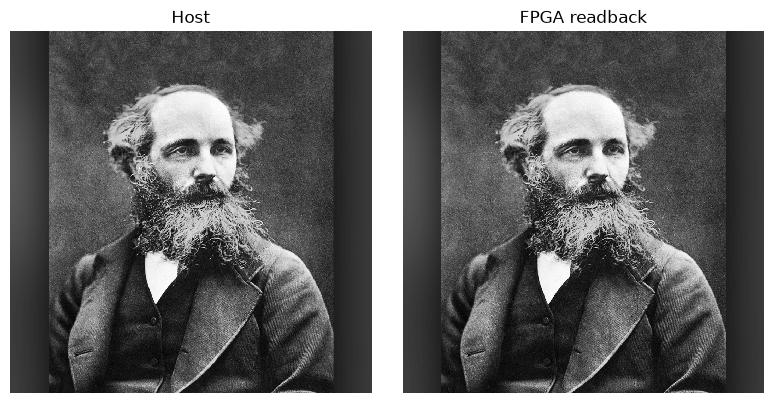

In [ ]:
def ddr3_write_read(img_host:Image):
  payload_host = img_host.tobytes()
  payload_fpga = bytearray()
  callbacks = {"write":[], "read":[]}

  with socket.socket(socket.AF_INET, socket.SOCK_DGRAM) as sock:
    sock.settimeout(5)
    sock.connect((FPGA_IP, FPGA_PORT))

    for offset in range(0, WIDTH * HEIGHT, CHUNK):
      block = payload_host[offset:offset+CHUNK]
      callback = send_to_fpga(sock, block, BASE_ADDRESS + offset, LENGTH)
      callbacks["write"].append(callback)

    for offset in range(0, WIDTH * HEIGHT, CHUNK):
      block, callback = receive_from_fpga(sock, BASE_ADDRESS + offset, LENGTH)
      payload_fpga.extend(block)
      callbacks["read"].append(callback)

    fpga_img = payload_to_image(payload_fpga, (WIDTH, HEIGHT))
    print(f"Does the sent payload match the received payload? {payload_fpga == payload_host}")
    return fpga_img, callbacks

if __name__ == "__main__":
  img_host = prepare_img("Gioconda.jpg", (WIDTH, HEIGHT))
  img_fpga, callbacks = ddr3_write_read(img_host)

  write_error_cnt = 0
  read_error_cnt = 0

  for callback in callbacks["write"]:
    if (callback["status"] == WRITE_ERROR):
      #print(f"ERROR at package [ADDRESS: {callback["address"]}] [LENGTH: {callback["length"]}]")
      write_error_cnt += 1
  

  for callback in callbacks["write"]:
    if (callback["status"] == WRITE_ERROR):
      #print(f"ERROR at package [ADDRESS: {callback["address"]}] [LENGTH: {callback["length"]}]")
      read_error_cnt += 1

  print(f"Write Errors: {write_error_cnt}")
  print(f"Read Errors: {write_error_cnt}")

  display_images(img_host, img_fpga)

In [17]:
with socket.socket(socket.AF_INET, socket.SOCK_DGRAM) as sock:
    sock.bind(("", LOCAL_PORT))
    sock.connect((FPGA_IP, FPGA_PORT))
    sock.settimeout(5)

    sock.send(METADATA.pack(READ, 0x1000, 64))

    for i in range(64):
        try:
            packet = sock.recv(65535)
        except socket.timeout:
            print(f"Timeout after receiving {i} of 2 READ datagrams")
            break

        print(f"Reply {i + 1}: {len(packet)} bytes | {packet[:16].hex(' ')}")

Reply 1: 1024 bytes | 2c 26 78 bf b1 9f a0 95 89 8a 8d 88 80 81 88 8a
Reply 2: 16 bytes | 42 02 00 00 10 00 00 40 00 00 00 00 00 00 00 00
Timeout after receiving 2 of 2 READ datagrams
